In [57]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from scipy import stats
from subprocess import run, PIPE
import sys
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [58]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [59]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [60]:
ifs = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IFS_cycle4_future_cesm2_grid_summer_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']

ifs = ifs[1:30,:,:]

In [61]:
print(ifs)

<xarray.DataArray '__xarray_dataarray_variable__' (year: 29, lat: 32, lon: 288)> Size: 1MB
[267264 values with dtype=int32]
Coordinates:
  * lat      (lat) float64 256B 30.63 31.57 32.51 33.46 ... 57.96 58.9 59.84
  * lon      (lon) float64 2kB 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
Dimensions without coordinates: year


In [62]:
#Define the yearly mean temperature change
data_path = Path('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/2020-2050/yearly_tmean_30-60N')
files = sorted([str(f) for f in data_path.glob(f'30-60N_IFS_9-FESOM_5_daily_year_tmean_*.nc')])[:]
ifs_tmean = xr.open_mfdataset(files, engine='netcdf4',combine='by_coords')['2t']
ifs_tmean = ifs_tmean[1:30,:]
land_sea_ifs_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc')['lsm']
ifs_tmean_land = ifs_tmean.where(land_sea_ifs_zoom9 > 0, np.nan)
ifs_tmean_land_mean = ifs_tmean_land.mean(dim='value').load()
ifs_tmean_land_diff = ifs_tmean_land_mean - ifs_tmean_land_mean[0]

In [63]:
latitude = [30,60]
land_sea_cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
land_sea_cesm2 = land_sea_cesm2[0,:,:]
indexer = ((land_sea_cesm2.lat>=latitude[0]) & (land_sea_cesm2.lat<=latitude[1]))
land_sea_cesm2 = land_sea_cesm2.where(indexer,drop=True)
land_sea_cesm2 = land_sea_cesm2.assign_coords(lat=ifs.lat, lon=ifs.lon)
ifs_land = ifs.where(land_sea_cesm2 > 0, np.nan)

In [64]:
# 1D cos(lat) for CESM2

lat_weights = xr.DataArray(
    np.cos(np.deg2rad(ifs_land['lat'])),
    dims=['lat'],
    coords={'lat': ifs_land['lat']}
)


In [65]:
ifs_land_mean = ifs_land.weighted(lat_weights).mean(dim=['lat','lon'])
ifs_lin = stats.linregress(ifs_tmean_land_mean,ifs_land_mean)
print(ifs_lin)

LinregressResult(slope=1.8414498610047827, intercept=27.92663063376554, rvalue=0.6389323595389992, pvalue=0.00019106396219275174, stderr=0.4266757212108835, intercept_stderr=3.821176272418085)


In [66]:
# 1D cos(lat) for CESM2
lat_rad_cesm2 = np.deg2rad(ifs_land.lat)
coslat_cesm2 = np.cos(lat_rad_cesm2)

w_lat_cesm2 = xr.DataArray(
    coslat_cesm2,
    dims=['lat'],
    coords={'lat': ifs_land.lat}
)

# Broadcast to (lat, lon) on CESM2 land mask
w_cesm2_2d = w_lat_cesm2.broadcast_like(land_sea_cesm2)
w_cesm2_2d = w_cesm2_2d.where(land_sea_cesm2 > 0)


# Broadcast to full CESM2(domain: member, year, lat, lon)
w_ifs_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, ifs_land.shape),
    dims=ifs_land.dims,
    coords=ifs_land.coords,
)
w_ifs_land = w_ifs_full.where(land_sea_cesm2 > 0, np.nan)




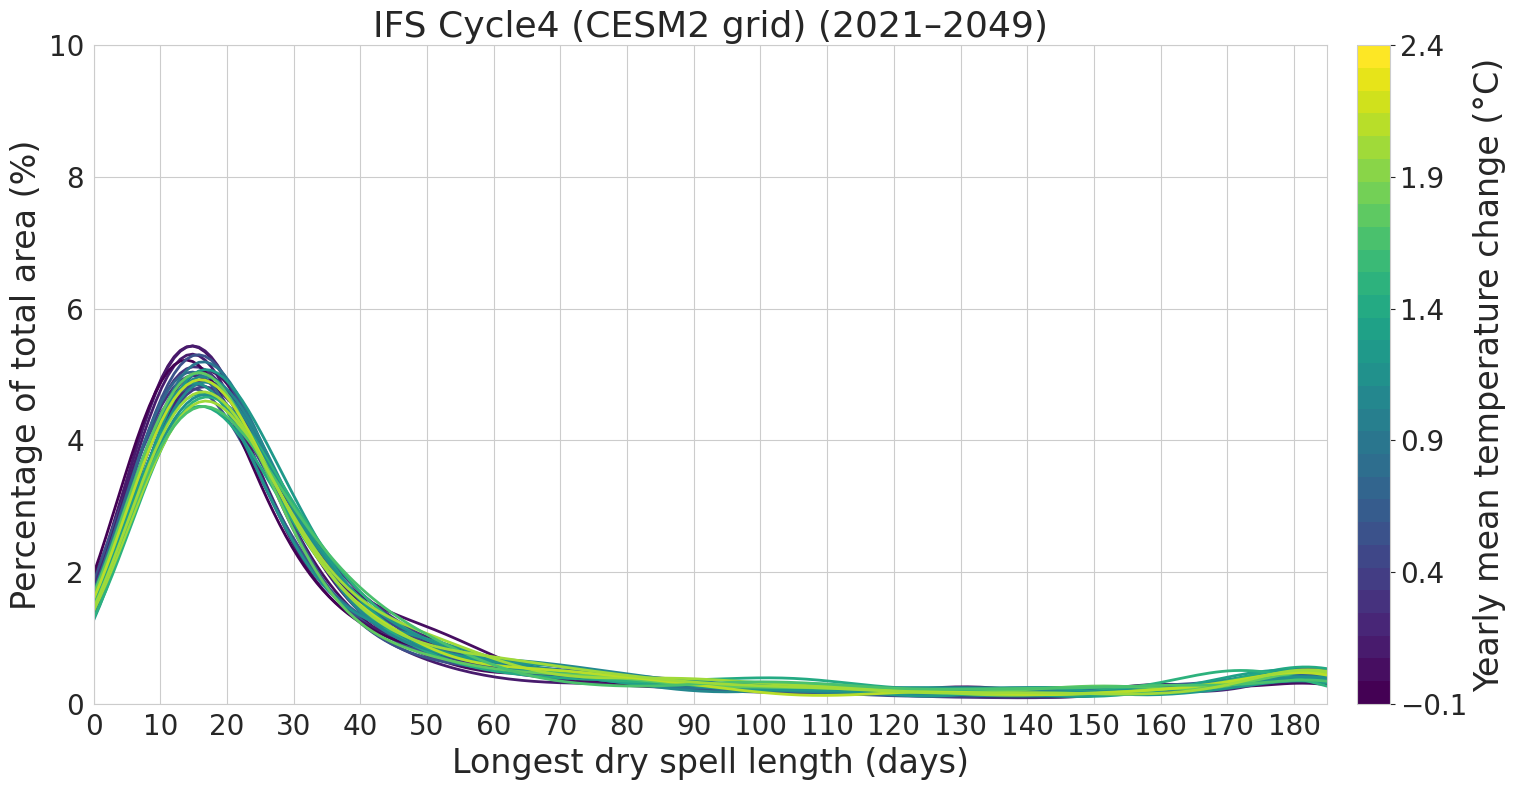

In [69]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Common x‐range + bin width
xmin, xmax = 0, 185
bin_width  = 2

# 2) Year indices (0–29) and number of years
years = ifs_land.year.values
n_years = len(years)

# 3) Viridis colormap
temps = ifs_tmean_land_diff.values
cmap = plt.get_cmap('viridis', n_years)
norm = plt.Normalize(
    vmin=-0.1,
    vmax=2.4
)

fig, ax = plt.subplots(figsize=(16, 8))
sns.set_style("whitegrid")

# Prepare to record the total weight for each year
sum_weights = []

# 4) Plot each year's KDE
for i, (yr, temp) in enumerate(zip(years, temps)):
    vals = ifs_land.sel(year=yr).values.ravel()
    vals = vals[~np.isnan(vals)]
    # weights that sum to 100
    w = np.ones_like(vals) * (100.0 / vals.size)
    sum_weights.append(w.sum())  # this will be 100.0 for each year

    sns.kdeplot(
        x=vals,
        weights=w,
        bw_adjust=1.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=cmap(norm(temp)),
        legend=False
    )

# 5) Rescale from “percent per unit‐x” → “percent per 0.5%‐bin”
for line, total_w in zip(ax.get_lines(), sum_weights):
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * bin_width * total_w
    line.set_data(x_vals, y_scaled)

sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)
sm.set_array([])

ticks = np.linspace(-0.1, 2.4, 6)

cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=ticks)
cbar.set_label('Yearly mean temperature change (°C)', fontsize=24)
cbar.ax.tick_params(labelsize=20)
xticks = np.arange(xmin, xmax, 10)
ax.set_xticks(xticks)

# 7) polish & save

xl = 'Longest dry spell length (days)'
ax.set_ylim(0, 10)


ax.set_xlabel(xl, fontsize=24)
plt.ylabel('Percentage of total area (%)', fontsize=24)
ax.set_xlim(xmin, xmax)
ax.tick_params(axis='both', which='major', labelsize=20)
plt.title('IFS Cycle4 (CESM2 grid) (2021–2049)', fontsize=26)
plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_IFS_cycle4_cesm2_grid_histo_dry_spell_temp.pdf', format='pdf',bbox_inches='tight')

plt.show()
